# 第12章 BipedalWalker：PPO で二本足のロボットを歩かせる

**BipedalWalker** は、二本足のロボットの4つの関節（左右の腰と膝）を動かして、でこぼこの地面を右の端まで歩かせる環境です。第11章の LunarLander と同じ Box2D の環境ですが、観測は 24 個の値、行動は 4 つの連続の値で、どちらも第11章より多くなります。

この章では、第11章の **PPO** を、RL Zoo の BipedalWalker 用の値で、Stable-Baselines3（SB3）で動かして楽しみます。その設定には、第11章には無かった **観測と報酬の正規化**（`VecNormalize`）が入っています。学習させたあと、正規化が何をしているかを、小さな NumPy のサンプルと SB3 のソースで読みます。最後に、ハイパーパラメータを自動で探す **Optuna** を、学習の短い第10章の Pendulum で体験します。

- **前提**: [第11章 LunarLander](../ch11_lunarlander/ch11_lunarlander.ipynb)を終えていること（PPO の仕組みは第11章の5節で読みました）。8節では、[第10章 Pendulum](../ch10_pendulum/ch10_pendulum.ipynb)の SAC を使います
- **所要の目安**: 実行は CPU で 2 時間半 ほど（著者の環境で、Notebook 全体を上から実行して約 153 分。そのうち、4節の PPO の学習が約 91 分、8-1節の Optuna が約 40 分です）
- **使う装置**: CPU で十分です（この章では GPU を使いません）

> **注記**
> - **出力の出どころ**: この Notebook に残っている出力は、著者の環境（Windows 11、CPU のみ、Gymnasium 1.3.0、Stable-Baselines3 2.9.0、PyTorch 2.14.1、Optuna 5.0.0）で 2026-10-24 に実行したものです。各セルの出力がそのまま期待する結果で、直後の「期待する結果」の段落に読み方を書いています。学習にかかる時間は、パソコンによって変わります。
> - **進め方**: セルを上から順に実行します。サンプルのプログラムは、読んで書き写す必要はありません。動かして、読んで、数字を変えて遊んでください。4節の学習は長いので、時間のあるときに始めてください。

## 0. 学習目標と完了条件

この章を終えると、次のことができるようになります。

1. BipedalWalker の観測・行動・報酬を説明できる
2. SB3 の PPO を RL Zoo の調整済みのハイパーパラメータ（観測と報酬の正規化を含む）で学習させ、成績と歩く様子を見られる
3. `VecNormalize` が観測と報酬をどう正規化しているかを、SB3 のソースの該当する行で示し、評価のときに正規化の統計を固定して使う理由を説明できる
4. Optuna でハイパーパラメータを探し、見つかった値を、学習の seed を変えて確かめられる

完了条件は、この Notebook を上から最後まで実行して、4節の PPO の **最後の時点のモデル** が、BipedalWalker-v3 の 100 回の評価で、次の2つを両方満たすことです。

- 報酬の合計の平均が **250 以上**
- 右の端まで **歩き切った回数が 90 回以上**

Gymnasium 1.3.0 に登録された BipedalWalker-v3 の「解けた」の目安（`reward_threshold`）は 300 です。この章の設定（学習の seed 0）では 300 に届かなかったので、完了条件は、著者が測った値をもとに上のように決めました（4-2節）。

## 1. 全体像

この章の流れは次のとおりです。

| 節 | すること | 見るもの |
|---|---|---|
| 3節 | 環境を知る：観測・行動・報酬 | でたらめな行動、何もしない場合、人が書いた規則の成績 |
| 4節 | 動かして楽しむ：SB3 の PPO | 成績、歩く様子 |
| 5節 | 読む：観測と報酬の正規化（`VecNormalize`） | 正規化の統計、NumPy のサンプル、正規化を外した成績 |
| 6節 | 学習の経過を見る | 学習中の評価、SAC で試した結果 |
| 7節 | ハードコア版で試す | 障害物のある地面での成績 |
| 8節 | Optuna でハイパーパラメータを探す（Pendulum） | 試した値と成績、seed を変えた比べ方 |
| 9節 | 遊んでみる | 試してみる設定 |

PPO は、概要資料の[強化学習の手法の地図](../../overview/rl.md)で「ニューラルネットワークで近似する」領域の、**方策オン** の Actor-Critic の手法です。この章で新しく出てくる `VecNormalize` と Optuna は、手法そのものではなく、学習を助ける道具です。

## 2. 準備

使うライブラリを読み込み、この章で何度も使う関数を用意します。

In [1]:
import time
from pathlib import Path

import gymnasium as gym
import imageio
import matplotlib.pyplot as plt
import numpy as np
import optuna
from gymnasium.envs.box2d.bipedal_walker import BipedalWalkerHeuristics
from IPython.display import Image
from stable_baselines3 import PPO, SAC
from stable_baselines3.common.callbacks import EvalCallback
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import VecNormalize

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)


def make_walker(hardcore=False):
    return gym.make("BipedalWalkerHardcore-v3" if hardcore else "BipedalWalker-v3")


# make_env() で作った環境で、方策 policy（観測 → 行動を返す関数）で episodes 回遊ばせる
# 報酬の合計の平均と標準偏差と、エピソードの終わり方の回数を返す
def evaluate(policy, episodes=100, seed=100, make_env=make_walker):
    env = make_env()
    totals = np.zeros(episodes)
    endings = {"歩き切った": 0, "転んだ": 0, "打ち切り": 0}
    for i in range(episodes):
        observation, info = env.reset(seed=seed + i)
        while True:
            observation, reward, terminated, truncated, info = env.step(policy(observation))
            totals[i] += reward
            if terminated or truncated:
                break
        if terminated:
            endings["転んだ" if reward == -100 else "歩き切った"] += 1
        else:
            endings["打ち切り"] += 1
    return totals.mean(), totals.std(), endings


# 方策 policy で1エピソード遊ばせ、every ステップごとの (ステップ数, 絵) の一覧を返す
# （絵は Gymnasium の描画）
def record_episode(policy, seed, every):
    env = gym.make("BipedalWalker-v3", render_mode="rgb_array")
    observation, info = env.reset(seed=seed)
    shots = [(0, env.render())]
    steps = 0
    while True:
        observation, reward, terminated, truncated, info = env.step(policy(observation))
        steps += 1
        if steps % every == 0 or terminated or truncated:
            shots.append((steps, env.render()))
        if terminated or truncated:
            return shots


# SB3 のモデルで、決まった行動を選ぶ方策を返す。
# norm（VecNormalize）を渡すと、観測を正規化してからモデルに渡す
def sb3_policy(model, norm=None):
    if norm is None:
        return lambda observation: model.predict(observation, deterministic=True)[0]
    return lambda observation: model.predict(norm.normalize_obs(observation),
                                             deterministic=True)[0]

D:\gymnasium-rl-textbook\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


関数の説明:

- `make_walker` は、BipedalWalker-v3 を作ります。`hardcore=True` で、障害物のあるハードコア版（`BipedalWalkerHardcore-v3`、7節）になります
- `evaluate` は、第11章と同じく、100 回それぞれの `reset` に `seed=100`〜`199` を渡して遊ばせ、エピソードの終わり方（3-1節）を数えて返します。報酬 -100 で終わった回を「転んだ」と数えるので、左の端より外に出た回（3-1節）も「転んだ」に入ります。8節では、Pendulum の評価にも使います（Pendulum は途中で終わらないので、終わり方はすべて「打ち切り」になります）
- `record_episode` は、第11章と同じ関数です
- `sb3_policy` には、`norm` を足しました。4節のモデルは、正規化した観測で学習しているので、評価でも観測を同じように正規化してから渡します（5節）

このセルを実行すると、`TqdmWarning: IProgress not found` という警告が出ることがあります。Optuna（8節）が読み込む tqdm（進み具合を表示する部品）の警告です（Optuna 5.0.0 の `optuna/progress_bar.py` が `tqdm.auto` を読み込みます）。この Notebook では進み具合の表示を使わないので、そのまま進めてかまいません。

## 3. 環境を知る：観測・行動・報酬

### 3-1. 観測と行動の空間

**BipedalWalker-v3** のロボットは、地面の左の端に立った状態で始まります。地面は少しでこぼこしていて、形はエピソードごとに変わります（Gymnasium 1.3.0 の `bipedal_walker.py` の環境の説明と `reset` の処理）。

In [2]:
env = make_walker()
print("観測の空間:", env.observation_space.shape, env.observation_space.dtype)
print("行動の空間:", env.action_space)
observation, info = env.reset(seed=0)
print("最初の観測:", np.round(observation, 2))

観測の空間: (24,) float32
行動の空間: Box(-1.0, 1.0, (4,), float32)
最初の観測: [ 0.   -0.    0.   -0.02  0.09 -0.    0.86  0.    1.    0.03 -0.    0.85
  0.    1.    0.44  0.45  0.46  0.49  0.53  0.6   0.71  0.89  1.    1.  ]


**期待する結果**（上の出力の読み方）: 観測は 24 個の値（`float32`）、行動は -1〜1 の4つの値の組（`Box(-1.0, 1.0, (4,), float32)`）です。`seed=0` で始めたときの最初の観測では、番号 8 と 13（脚が地面に着いているか）がどちらも 1.0 で、両方の脚が地面に着いています。番号 14〜23（ライダー）は、0.44 から番号が大きいほど大きくなり、番号 22 と 23 は 1.0 です。

観測の 24 個の値は、次のとおりです（`bipedal_walker.py` の `step` の処理）。位置の座標は入っていません。

| 番号 | 値 |
|---|---|
| 0〜3 | 胴体の傾きの角度、角速度、横の速さ、縦の速さ |
| 4〜8 | 1本目の脚：腰の関節の角度・速さ、膝の関節の角度（+1.0 ずらした値）・速さ、地面に着いているか（着いていれば 1.0） |
| 9〜13 | 2本目の脚：4〜8 と同じ並び |
| 14〜23 | 胴体から前の下のほうへ伸ばした 10 本の距離のセンサー（ライダー）。地面に当たるまでの距離を、センサーの長さを 1.0 として表した値（当たらなければ 1.0） |

- 行動（4つの値、どちらも -1〜1）: 1本目の腰、1本目の膝、2本目の腰、2本目の膝のモーターです。値の符号で回す向きが、絶対値で力（トルク）の上限が決まります（`step` の処理）
- 報酬: 1ステップごとに、胴体が右へ進んだ分だけ増えます（右の端まで進むと、合わせて 300 ほどになるように決められています）。胴体が傾くと減り、モーターに力を出させると、その大きさに応じて少し減ります
- 終わり方: 胴体が地面に触れる（転ぶ）か、左の端より外に出ると、そのステップの報酬を -100 にして終わります。右の端まで進むと、そこで終わります。どちらも無ければ、1,600 ステップで打ち切られます（`truncated`）

報酬と終わり方は、`bipedal_walker.py` の環境の説明と `step` の処理、`gymnasium/envs/__init__.py` の登録（`max_episode_steps=1600`）で確かめました。

### 3-2. でたらめな行動・何もしない場合・人が書いた規則で 100 回ずつ遊ぶ

Gymnasium の `bipedal_walker.py` には、人が書いた歩き方の規則（`BipedalWalkerHeuristics`）が入っています。片方の脚で立つ、もう片方の脚を前に下ろす、蹴り出す、の3つの状態を順に切り替えながら、関節の角度を目標に近づける規則です。ソースのコメントには、最適ではなく、釣り合いの考えも入っていないと書かれています。

In [3]:
env = make_walker()
env.action_space.seed(0)


# 人が書いた規則（BipedalWalkerHeuristics）で episodes 回遊ばせる。
# 規則は今の状態（片方の脚で立つ等）を覚えているので、エピソードごとに作り直し、
# 1 回ずつ evaluate で評価して足し合わせる
def heuristic_episodes(make_env=make_walker, episodes=100, seed=100):
    totals, endings = [], {"歩き切った": 0, "転んだ": 0, "打ち切り": 0}
    for i in range(episodes):
        mean, std, ends = evaluate(BipedalWalkerHeuristics().step_heuristic,
                                   episodes=1, seed=seed + i, make_env=make_env)
        totals.append(mean)
        for key in endings:
            endings[key] += ends[key]
    return np.mean(totals), np.std(totals), endings


for name, result in [("でたらめな行動", evaluate(lambda observation: env.action_space.sample())),
                     ("何もしない", evaluate(lambda observation: np.zeros(4, dtype=np.float32))),
                     ("人が書いた規則", heuristic_episodes())]:
    mean, std, endings = result
    print(f"{name}: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}")

でたらめな行動: 報酬の合計の平均 -97.0、標準偏差 14.2、{'歩き切った': 0, '転んだ': 59, '打ち切り': 41}
何もしない: 報酬の合計の平均 -91.9、標準偏差 0.1、{'歩き切った': 0, '転んだ': 100, '打ち切り': 0}
人が書いた規則: 報酬の合計の平均 38.1、標準偏差 108.0、{'歩き切った': 3, '転んだ': 93, '打ち切り': 4}


**期待する結果**（上の出力の読み方）: でたらめな行動は平均 -97.0 で、100 回のうち 59 回転び、41 回は 1,600 ステップで打ち切られました。何もしない（4つの値を 0 にする）と、100 回とも転び、平均は -91.9 でした。人が書いた規則は平均 38.1（標準偏差 108.0）で、右の端まで歩き切ったのは 3 回、転んだのは 93 回でした。

人が書いた規則の成績は、遊ばせ方によって変わることがありました。この Notebook の `heuristic_episodes` は、`evaluate` を 1 回ずつ呼ぶので、エピソードごとに環境を作り直します。著者がこの手順を新しいプロセスで2回実行したところ、2回とも上の出力と同じ値でした（7節のハードコア版も同じ）。一方、1つの環境を作って、同じ 30 個の seed（100〜129）で2回続けて遊ばせたところ、平均は 86.9 と 40.3 で、報酬の合計が一致したのは 30 回のうち 11 回でした（原因は確かめていません）。

## 4. 動かして楽しむ：SB3 の PPO

### 4-1. 学習させる

ハイパーパラメータは、**RL Zoo** の BipedalWalker-v3 用の値です（出典は末尾）。RL Zoo の値は、次の表のとおりです。書いていない設定は SB3 の既定値で、ネットワークは、第11章と同じく、方策と価値の見積もりで別々の 64 × 64 です（SB3 2.9.0 の `stable_baselines3/common/policies.py`）。

| 設定 | RL Zoo の値 | 第11章（LunarLander） | 意味 |
|---|---|---|---|
| `normalize` | true | （無し） | 観測と報酬を正規化する（`VecNormalize`、5節） |
| `n_envs` | 32 | 16 | 同時に動かす環境の数 |
| `n_timesteps` | 5,000,000 | 1,000,000 | 学習のステップ数（32 個の環境の合計） |
| `n_steps` | 2048 | 1024 | 1回の更新の前に、1つの環境で集めるステップ数 |
| `batch_size` | 64 | 64 | 重みを1回動かすのに使う経験の数 |
| `n_epochs` | 10 | 4 | 集めた経験を、何周使って重みを動かすか |
| `gamma` | 0.999 | 0.999 | 割引率 |
| `gae_lambda` | 0.95 | 0.98 | GAE の λ |
| `ent_coef` | 0.0 | 0.01 | エントロピーの項の重み |
| `learning_rate` | 0.0003 | （既定値 0.0003） | 学習率 |
| `clip_range` | 0.18 | （既定値 0.2） | 確率の比をクリップする幅（第11章の5-3節） |

RL Zoo は、`normalize: true` のとき、学習用の環境を `VecNormalize` で包み、その割引率 `gamma` に、PPO の `gamma` と同じ値を渡します。学習中の評価に使う環境は、報酬を正規化せず、正規化の統計も更新しない設定（`norm_reward=False`、`training=False`）で包みます（RL Zoo v2.9.0 の `rl_zoo3/exp_manager.py`）。次のセルも、同じようにしています。

学習中の様子を見るために、`EvalCallback` で、250,000 ステップごとに 5 回遊ばせて評価します。著者の環境では 5,452 秒（約 91 分）かかりました。

In [4]:
# RL Zoo（v2.9.0）の PPO の BipedalWalker-v3 用のハイパーパラメータ（出典は末尾）
PPO_PARAMS = dict(n_steps=2048, batch_size=64, gae_lambda=0.95, gamma=0.999, n_epochs=10,
                  ent_coef=0.0, learning_rate=3e-4, clip_range=0.18)

seed = 0
train_env = VecNormalize(make_vec_env("BipedalWalker-v3", n_envs=32, seed=seed),
                         gamma=PPO_PARAMS["gamma"])
eval_env = VecNormalize(make_vec_env("BipedalWalker-v3", n_envs=1, seed=1000 + seed),
                        training=False, norm_reward=False)
# eval_freq は1つの環境のステップ数で数えるので、
# 32 個の環境の合計で 250,000 ステップごとになるように割る
callback = EvalCallback(eval_env, n_eval_episodes=5, eval_freq=250_000 // 32,
                        log_path="checkpoints/ppo_walker", verbose=0)
model = PPO("MlpPolicy", train_env, seed=seed, device="cpu", tensorboard_log="logs", **PPO_PARAMS)
start = time.perf_counter()
model.learn(total_timesteps=5_000_000, callback=callback, tb_log_name="ppo_walker")
print(f"学習にかかった時間: {time.perf_counter() - start:.0f} 秒")
print("学習したステップ数:", model.num_timesteps)
print("250,000 ステップごとの評価（5 回の平均）:",
      np.round(np.mean(callback.evaluations_results, axis=1), 1))

学習にかかった時間: 5452 秒
学習したステップ数: 5046272
250,000 ステップごとの評価（5 回の平均）: [-93.8 -29.1 -34.6   6.9  72.  138.7 158.9  70.7 261.7 287.1 290.  290.4
 290.7 269.5 290.2 157.3 292.6 296.1 259.9 292.6]


**期待する結果**（上の出力の読み方）: 学習には 5,452 秒（約 91 分）かかり、学習したステップ数は 5,046,272 でした。250,000 ステップごとの評価は、1 回目の -93.8 から上がり、9 回目（約 2,250,000 ステップ）で 261.7 になりました。9 回目からの 12 回は、16 回目（約 4,000,000 ステップ）の 157.3 を除いて、259.9〜296.1 の間です。

学習したステップ数が 5,000,000 ちょうどでないのは、PPO が「32 個の環境で 2048 ステップずつ集める」（合わせて 65,536 ステップ）ことを1回の単位にして、5,000,000 に届くまで繰り返すためです（第11章の5-1節。SB3 2.9.0 の `stable_baselines3/common/on_policy_algorithm.py` の `learn`）。

`seed=0`（学習）と `seed=1000`（学習中の評価の環境）を固定しています。`EvalCallback` は、評価の前に、学習用の環境の正規化の統計を、評価用の環境に写します（SB3 2.9.0 の `stable_baselines3/common/callbacks.py` の `sync_envs_normalization`）。`checkpoints` フォルダと `logs` フォルダは、学習のたびに作り直せるものなので、Git の管理から外しています。学習の記録を TensorBoard で見る手順は、[第1章](../ch01_first_training/ch01_first_training.ipynb)の6-2節と同じです（フォルダを `chapters\ch12_bipedalwalker\logs` にします）。

### 4-2. 成績を測る

最後の時点のモデルを、100 回評価します。観測は、学習用の環境 `train_env` が学習中に集めた正規化の統計で正規化してから、モデルに渡します。

In [5]:
mean, std, endings = evaluate(sb3_policy(model, norm=train_env))
print(f"最後の時点のモデル: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}")

最後の時点のモデル: 報酬の合計の平均 287.3、標準偏差 38.9、{'歩き切った': 97, '転んだ': 3, '打ち切り': 0}


**期待する結果**（上の出力の読み方）: 最後の時点のモデルは、100 回の平均が 287.3（標準偏差 38.9）で、右の端まで歩き切ったのが 97 回、転んだのが 3 回でした。完了条件（平均 250 以上、歩き切り 90 回以上）を両方満たしています。「解けた」の目安の 300 には届いていません。

4-2節の値は、著者が別に動かした試作のスクリプト（同じ設定と seed）で測った値と同じでした。この章では、学習の seed を 0 だけで測りました。学習には長い時間がかかるので、seed を変えた成績は測っていません。seed を変えると、成績が変わる場合があります（第7章・第11章では、seed によって成績が変わりました）。

### 4-3. 歩く様子を見る

最後の時点のモデルで1エピソード遊ばせ、8 ステップごとの絵を GIF に保存します。BipedalWalker の描画は 1 秒に 50 ステップ（`render_fps`）なので、1 枚を 160 ミリ秒で表示すると、ほぼその速さです。画面は、ロボットに合わせて右へ動きます。

エピソードのステップ数: 1179


GIF の枚数: 149


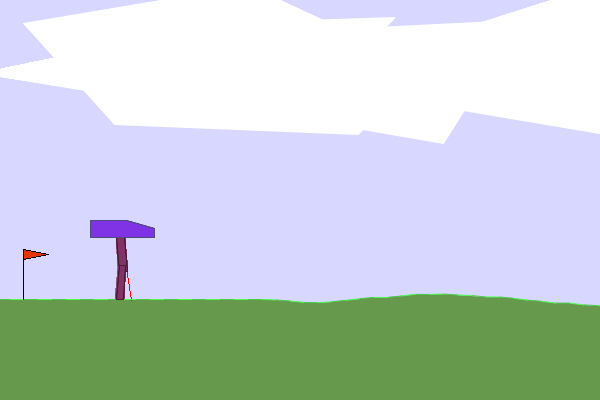

In [6]:
shots = record_episode(sb3_policy(model, norm=train_env), seed=0, every=8)
print("エピソードのステップ数:", shots[-1][0])
imageio.v3.imwrite(FIGURES / "ch12_ppo_walker.gif", [frame for _, frame in shots],
                   duration=160, loop=0)
print("GIF の枚数:", len(shots))
Image(filename=FIGURES / "ch12_ppo_walker.gif")

**期待する結果**（上の出力の読み方）: このエピソードは 1,179 ステップで終わり、GIF は 149 枚になりました（最初の絵、8 ステップごとの絵、最後の絵）。

**期待する結果**（VS Code などで実行した場合）: 出力に GIF が動いて表示されます。ロボットは、左の端の旗のそばから歩き出します。濃い色の脚を前へ大きく振り出し、薄い色の脚は膝を曲げて後ろに残したまま、胴体を上下に傾けながら右へ進みます。最後は地面の右の端に着いて、エピソードが終わります。

GitHub でこの Notebook を読んでいる場合、上の出力の GIF の動きは見られません（著者が、private だった 2026-10-01 に第0章で、public にした後の 2026-10-10 に第3〜5章で確かめました）。GIF は、この章のフォルダの [README.md](README.md) でも見られます。Notebook の中でも見られるように、次のセルで、同じエピソードのコマ送りの図を作ります。

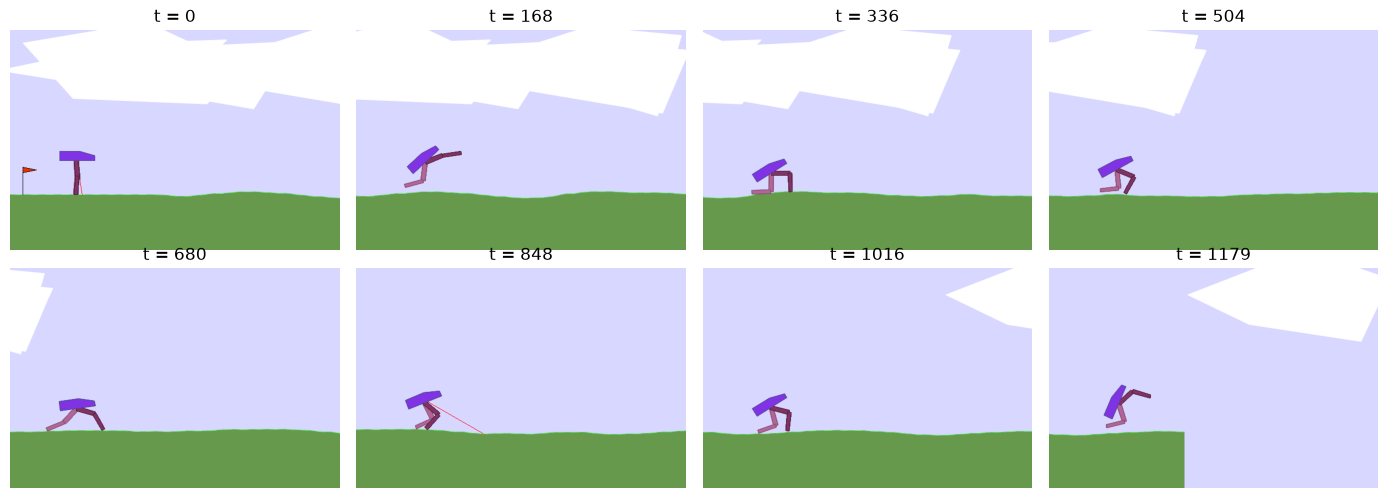

In [7]:
picks = np.linspace(0, len(shots) - 1, 8).round().astype(int)  # 等間隔に 8 枚選ぶ
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, i in zip(axes.flat, picks):
    t, frame = shots[i]
    ax.imshow(frame)
    ax.set_title(f"t = {t}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES / "ch12_ppo_walker_frames.png", dpi=80)
plt.show()

**期待する結果**（上の出力の読み方）: t = 0 では、ロボットは左の端の赤い旗のそばに立っています。t = 168〜1016 では、濃い色の脚を前に出し、薄い色の脚を後ろに曲げた姿勢で進んでいます。画面がロボットに合わせて右へ動くので、ロボットはいつも画面の左寄りに映ります。t = 1179 の絵では、地面がロボットの右で切れていて、右の端に着いたところです。

絵の中に、ロボットから伸びる赤い細い線が映ることがあります。これはライダーの1本を描いたもので、Gymnasium 1.3.0 の `bipedal_walker.py` の `render` は、描くたびに1本ずつ順に、100 回のうち 20 回だけ描きます。

## 5. 読む：観測と報酬の正規化（`VecNormalize`）

観測の 24 個の値は、番号によって、動く範囲が違います（5-1節の出力の標準偏差）。`VecNormalize` は、学習中に集めた観測から、値ごとの平均と分散を計算し続け、観測を「平均 0・標準偏差 1」に近づけてからモデルに渡します。報酬も、大きさをそろえてから学習に使います。この節では、4節の `train_env` と、SB3 2.9.0 の `stable_baselines3/common/vec_env/vec_normalize.py` を見ながら、その仕組みを読みます。

### 5-1. 学習中に集めた統計を見る

In [8]:
rms = train_env.obs_rms
names = ["hull angle", "angular vel", "x speed", "y speed", "hip 1 angle", "lidar 1", "lidar 10"]
picks = [0, 1, 2, 3, 4, 14, 23]
print("統計に使った観測の数:", int(rms.count))
for name, i in zip(names, picks):
    print(f"  {i:2d} {name:12s} 平均 {rms.mean[i]:+.3f}、標準偏差 {np.sqrt(rms.var[i]):.3f}")
observation, info = make_walker().reset(seed=0)
print("最初の観測（番号 0〜4）:      ", np.round(observation[:5], 3))
print("正規化した観測（番号 0〜4）:  ", np.round(train_env.normalize_obs(observation)[:5], 3))
print("報酬の正規化に使う標準偏差:", round(float(np.sqrt(train_env.ret_rms.var)), 3))
print("転んだときの報酬 -100 を正規化した値:",
      np.round(train_env.normalize_reward(np.array([-100.0])), 3))

統計に使った観測の数: 5046304
   0 hull angle   平均 +0.342、標準偏差 0.306
   1 angular vel  平均 +0.000、標準偏差 0.069
   2 x speed      平均 +0.226、標準偏差 0.160
   3 y speed      平均 -0.003、標準偏差 0.083
   4 hip 1 angle  平均 -0.610、標準偏差 0.414
  14 lidar 1      平均 +0.296、標準偏差 0.048
  23 lidar 10     平均 +0.996、標準偏差 0.020
最初の観測（番号 0〜4）:       [ 0.003 -0.     0.002 -0.016  0.092]
正規化した観測（番号 0〜4）:   [-1.106 -0.003 -1.398 -0.151  1.696]
報酬の正規化に使う標準偏差: 53.891
転んだときの報酬 -100 を正規化した値: [-1.856]


**期待する結果**（上の出力の読み方）: 統計に使った観測の数は 5,046,304 で、学習したステップ数（5,046,272）より 32 多い数です（最初の `reset` で返した 32 個の環境の観測の分）。標準偏差は、横の速さ（番号 2）が 0.160、角速度（番号 1）が 0.069、10 本目のライダー（番号 23）が 0.020 と、値によって違います。10 本目のライダーの平均は 0.996 で、ほとんどいつも 1.0（何にも当たらない）でした。最初の観測の番号 0〜4 は、正規化すると -1.106、-0.003、-1.398、-0.151、1.696 になります。報酬の正規化に使う標準偏差は 53.891 で、転んだときの報酬 -100 は、学習に使う値では -1.856 になります。

観測の正規化は、`vec_normalize.py` の `_normalize_obs` の次の行です。

```python
return np.clip((obs - obs_rms.mean) / np.sqrt(obs_rms.var + self.epsilon),
               -self.clip_obs, self.clip_obs)
```

観測から平均を引き、標準偏差で割って、-10〜10 に切り詰めます（`clip_obs=10.0` が既定値。`epsilon=1e-8` は 0 で割らないための小さな値です）。平均と分散 `obs_rms` は、学習用の環境が新しい観測を返すたびに更新されます（`training=True` のとき。`step_wait` と `reset` の処理）。

### 5-2. 平均と分散を少しずつ更新する

平均と分散は、学習の始めから集めたすべての観測で計算します。ただし、それまでの観測を全部とっておくわけではありません。SB3 の `stable_baselines3/common/running_mean_std.py` の `RunningMeanStd` は、「これまでの平均・分散・個数」と「新しく来た観測のまとまりの平均・分散・個数」から、合わせた平均と分散を計算します。次のセルは、その計算を NumPy で書き、全部をとっておいて計算した値と比べるものです。

In [9]:
# 2つのまとまりの (平均, 分散, 個数) から、合わせた平均と分散を計算する
# （RunningMeanStd.update_from_moments と同じ式）
def combine(mean_a, var_a, count_a, mean_b, var_b, count_b):
    delta = mean_b - mean_a
    count = count_a + count_b
    mean = mean_a + delta * count_b / count
    var = (var_a * count_a + var_b * count_b + delta**2 * count_a * count_b / count) / count
    return mean, var, count


rng = np.random.default_rng(0)
data = rng.normal(loc=3.0, scale=2.0, size=1000)  # 例として作った 1,000 個の値
mean, var, count = 0.0, 1.0, 1e-4  # RunningMeanStd の始めの値（個数は 0 で割らないための小さな値）
for batch in np.split(data, 10):  # 100 個ずつ 10 回に分けて届いたとする
    mean, var, count = combine(mean, var, count, batch.mean(), batch.var(), len(batch))
print(f"少しずつ更新した値: 平均 {mean:.4f}、分散 {var:.4f}")
print(f"全部で計算した値:   平均 {data.mean():.4f}、分散 {data.var():.4f}")

少しずつ更新した値: 平均 2.9039、分散 3.8162
全部で計算した値:   平均 2.9039、分散 3.8162


**期待する結果**（上の出力の読み方）: 100 個ずつ 10 回に分けて更新した平均と分散（2.9039、3.8162）は、1,000 個を全部とっておいて計算した値と、表示した桁まで同じです。

- `delta` は、2つのまとまりの平均の差です。合わせた平均は、これまでの平均を、新しいまとまりの側へ、個数の割合だけ動かした値になります
- 合わせた分散には、それぞれの分散に加えて、2つの平均がずれている分（`delta**2` の項）も入ります
- 4節の学習では、32 個の環境が1ステップ進むたびに、32 個の観測を1つのまとまりとして更新しています（`step_wait` の `self.obs_rms.update(obs)`。最初の `reset` で返す観測でも更新します）

### 5-3. 報酬の正規化

報酬は、観測とは少し違うやり方で正規化します。`vec_normalize.py` の次の行です。

```python
# _update_reward
self.returns = self.returns * self.gamma + reward
self.ret_rms.update(self.returns)
# normalize_reward
reward = np.clip(reward / np.sqrt(self.ret_rms.var + self.epsilon),
                 -self.clip_reward, self.clip_reward)
```

- 環境ごとに、それまでの報酬を割引率 `gamma`（ここでは 0.999）で割り引いて足した値 `returns` を持ち、その分散を `ret_rms` で計算し続けます。エピソードが終わると、その環境の `returns` は 0 に戻ります（`step_wait` の `self.returns[dones] = 0`）
- 報酬は、その標準偏差で割り、-10〜10 に切り詰めます（`clip_reward=10.0` が既定値）。観測と違って、平均は引きません
- 5-1節の出力の最後の行は、転んだときの報酬 -100 を、学習の最後の時点の統計で正規化した値です

`evaluate` で測る報酬の合計は、環境が返した元の報酬で数えています。正規化した報酬は、学習の中だけで使われます。

### 5-4. 評価のときは、学習中の統計で正規化する

4節のモデルは、正規化した観測を見て行動を選ぶように学習しています。評価のときも、学習中に集めた統計で、同じように正規化してから観測を渡す必要があります。試しに、正規化を外して（元の観測をそのまま渡して）100 回評価します。

In [10]:
mean, std, endings = evaluate(sb3_policy(model))
print(f"正規化を外した場合: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}")

正規化を外した場合: 報酬の合計の平均 -99.7、標準偏差 1.1、{'歩き切った': 0, '転んだ': 100, '打ち切り': 0}


**期待する結果**（上の出力の読み方）: 観測を正規化せずに渡すと、100 回とも転び、平均は -99.7 でした。4-2節（平均 287.3、歩き切り 97 回）と同じモデルです。

このため、正規化の統計は、モデルとは別に保存する必要があります。SB3 では、モデルを `model.save(...)` で、正規化の統計を `train_env.save(...)` で保存し、使うときは `VecNormalize.load(...)` で読み込みます（評価に使うときは、読み込んだあと `training=False`、`norm_reward=False` にします）。評価の途中で統計を更新しないように、評価用の環境は `training=False` で作ります（4-1節の `eval_env`）。

## 6. 学習の経過を見る

### 6-1. 学習中の評価

4節の、学習中の評価（5 回の平均）を並べます。

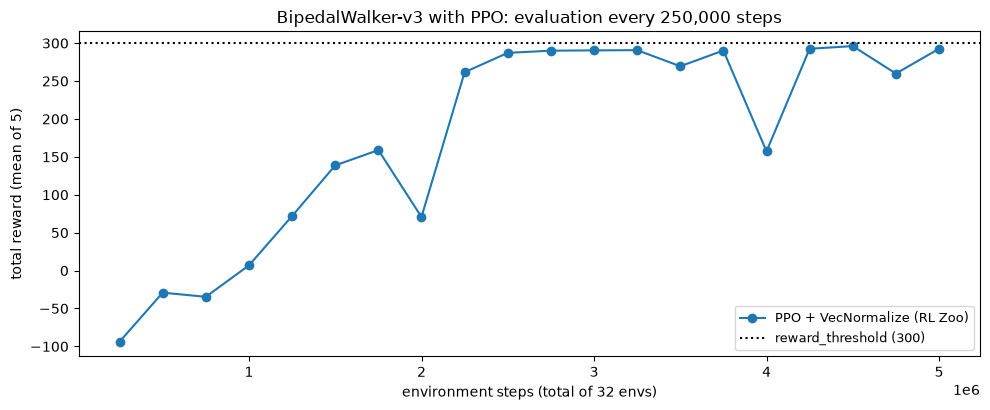

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(callback.evaluations_timesteps, np.mean(callback.evaluations_results, axis=1), "o-",
        color="tab:blue", label="PPO + VecNormalize (RL Zoo)")
ax.axhline(300, color="black", linestyle=":", label="reward_threshold (300)")
ax.set_xlabel("environment steps (total of 32 envs)")
ax.set_ylabel("total reward (mean of 5)")
ax.set_title("BipedalWalker-v3 with PPO: evaluation every 250,000 steps")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "ch12_learning_curve.png", dpi=80)
plt.show()

**期待する結果**（上の出力の読み方）: 青い丸は、始めの -93.8 から上がり、1,750,000 ステップで 158.9 になったあと、2,000,000 ステップで 70.7 に下がり、2,250,000 ステップで 261.7 に上がりました。そのあとは、4,000,000 ステップの 157.3 を除いて 259.9〜296.1 の間にあり、点線の 300 には届いていません。

### 6-2. SAC でも試した結果（参考）

この章の手法を決める前に、著者は、第10章の SAC でも BipedalWalker を学習させました。RL Zoo v2.9.0 の SAC の BipedalWalker-v3 用の値（500,000 ステップ。`use_sde=True` や、400 × 300 のネットワークを使う設定）で、学習の seed は 0 だけです。この Notebook では動かしていません。評価は、この Notebook の `evaluate` と同じ 100 回、最後の時点のモデルです。

| 手法 | 学習のステップ数 | 報酬の合計の平均 | 標準偏差 | 歩き切った | 転んだ | 1回のステップ数の平均 |
|---|---|---|---|---|---|---|
| PPO（4節のモデル） | 5,000,000 | 287.3 | 38.9 | 97 回 | 3 回 | 1152.6 |
| SAC | 500,000 | 215.7 | 156.5 | 64 回 | 36 回 | 570.6 |

PPO の行の「1回のステップ数の平均」は、同じ設定と seed で動かした著者の試作のスクリプトで測った値です（試作の平均・標準偏差・終わり方は、4-2節の出力と同じでした）。学習のステップ数は設定の値で、PPO が実際に学習したのは、4-1節のとおり 5,046,272 ステップです。

- この設定と seed では、SAC の最後の時点のモデルは、PPO より平均が低く、100 回のうち 36 回転びました
- 1回のステップ数の平均は、SAC が PPO の半分ほどでした（転んだ回も含めた平均です）
- SAC の学習中の評価（25,000 ステップごとに 5 回の平均）は、475,000 ステップで 325.6 でしたが、最後の 500,000 ステップでは 271.5 でした

seed 1 つずつの比較なので、どちらの手法が BipedalWalker に向いているかは、これだけでは言えません。RL Zoo が公開している学習済みのエージェントの成績（v2.9.0 の `benchmark.md`。それぞれ1回の学習）では、BipedalWalker-v3 の平均は PPO が 287.9、SAC が 297.7 です。

## 7. ハードコア版で試す

**BipedalWalkerHardcore-v3** は、地面に、階段（上りと下り）、切り株、穴が出てくる版です（`bipedal_walker.py` の地面を作る処理 `_generate_terrain`）。打ち切りは 2,000 ステップで、「解けた」の目安は同じく 300 です（`gymnasium/envs/__init__.py` の登録）。通常版で学習した4節のモデルを、ハードコア版で 100 回評価します。比べるために、3-2節の人が書いた規則でも 100 回評価します。

In [12]:
make_hardcore = lambda: make_walker(hardcore=True)
for name, result in [("PPO（4節のモデル）",
                      evaluate(sb3_policy(model, norm=train_env), make_env=make_hardcore)),
                     ("人が書いた規則", heuristic_episodes(make_env=make_hardcore))]:
    mean, std, endings = result
    print(f"{name}（ハードコア版）: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}")

PPO（4節のモデル）（ハードコア版）: 報酬の合計の平均 -78.9、標準偏差 35.9、{'歩き切った': 0, '転んだ': 64, '打ち切り': 36}
人が書いた規則（ハードコア版）: 報酬の合計の平均 -64.1、標準偏差 26.0、{'歩き切った': 0, '転んだ': 93, '打ち切り': 7}


**期待する結果**（上の出力の読み方）: 4節のモデルは、ハードコア版では 100 回とも右の端まで歩き切れず、64 回転び、36 回は 2,000 ステップで打ち切られました（平均 -78.9）。人が書いた規則も歩き切れず、93 回転びました（平均 -64.1）。平均は、人が書いた規則のほうが高くなっています。

RL Zoo の `ppo.yml` には、ハードコア版用の値もあります（学習のステップ数は 100,000,000）。

## 8. Optuna でハイパーパラメータを探す（Pendulum）

### 8-1. 探す

ここまでは、RL Zoo の調整済みの値を使ってきました。**Optuna** は、ハイパーパラメータの値を変えながら学習と評価を繰り返し、成績のよい値を探すライブラリです。1 回の試し（trial）ごとに、それまでの結果を見て、次に試す値を選びます（この章では、Optuna の既定の選び方の TPE〈`TPESampler`〉を使います）。

BipedalWalker では 1 回の学習に長い時間がかかるので、ここでは、第10章の Pendulum の SAC で試します。第10章では 20,000 ステップ学習させましたが、ここでは、1 回の試しを短くするために 10,000 ステップにして、その長さで成績がよくなる値を探します。探すのは、次の3つです。

| 設定 | 探す範囲 | 第10章（RL Zoo の値・SB3 の既定値） |
|---|---|---|
| `learning_rate` | 0.0001〜0.01（対数の目盛りで選ぶ） | 0.001（RL Zoo） |
| `gamma` | 0.9〜0.999 | 0.99（SB3 の既定値） |
| `tau` | 0.001〜0.05（対数の目盛りで選ぶ） | 0.005（SB3 の既定値） |

最初の試しには、第10章の値を入れておきます（`enqueue_trial`）。1 回の試しの評価は、Pendulum の 10 回の平均で、`reset` の seed は 1000〜1009 です（8-2節の確かめに使う 100〜199 とは分けています）。著者の環境では 2,426 秒ほどかかりました。

In [13]:
def make_pendulum():
    return gym.make("Pendulum-v1")


# 第10章の値（RL Zoo の learning_rate と、SB3 の既定値）
ZOO_PARAMS = dict(learning_rate=1e-3, gamma=0.99, tau=0.005)


# SAC で Pendulum を学習させたモデルを返す
def train_sac_pendulum(params, seed, total_timesteps=10_000):
    model = SAC("MlpPolicy", make_pendulum(), seed=seed, device="cpu", **params)
    model.learn(total_timesteps=total_timesteps)
    return model


# Optuna が 1 回の試しごとに呼ぶ関数。
# trial が選んだ値で学習させ、評価の成績を返す（大きいほどよい）
def objective(trial):
    params = dict(learning_rate=trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
                  gamma=trial.suggest_float("gamma", 0.9, 0.999),
                  tau=trial.suggest_float("tau", 0.001, 0.05, log=True))
    model = train_sac_pendulum(params, seed=0)
    return evaluate(sb3_policy(model), episodes=10, seed=1000, make_env=make_pendulum)[0]


optuna.logging.set_verbosity(optuna.logging.WARNING)  # 試しごとの長いログを出さない
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
study.enqueue_trial(ZOO_PARAMS)
start = time.perf_counter()
study.optimize(objective, n_trials=20)
print(f"探すのにかかった時間: {time.perf_counter() - start:.0f} 秒")
for trial in study.trials:
    p = trial.params
    print(f"  試し {trial.number:2d}: learning_rate {p['learning_rate']:.5f}、"
          f"gamma {p['gamma']:.3f}、tau {p['tau']:.4f} → {trial.value:.1f}")
print("一番よかった試し:", study.best_trial.number,
      {k: round(v, 5) for k, v in study.best_params.items()}, round(study.best_value, 1))

探すのにかかった時間: 2426 秒
  試し  0: learning_rate 0.00100、gamma 0.990、tau 0.0050 → -169.8
  試し  1: learning_rate 0.00125、gamma 0.971、tau 0.0106 → -170.7
  試し  2: learning_rate 0.00123、gamma 0.942、tau 0.0125 → -177.5
  試し  3: learning_rate 0.00075、gamma 0.988、tau 0.0434 → -171.2
  試し  4: learning_rate 0.00058、gamma 0.978、tau 0.0079 → -170.7
  試し  5: learning_rate 0.00137、gamma 0.992、tau 0.0013 → -228.1
  試し  6: learning_rate 0.00015、gamma 0.902、tau 0.0260 → -224.0
  試し  7: learning_rate 0.00360、gamma 0.986、tau 0.0460 → -167.7
  試し  8: learning_rate 0.00397、gamma 0.946、tau 0.0212 → -180.5
  試し  9: learning_rate 0.00017、gamma 0.963、tau 0.0018 → -210.1
  試し 10: learning_rate 0.00952、gamma 0.957、tau 0.0038 → -176.9
  試し 11: learning_rate 0.00561、gamma 0.987、tau 0.0244 → -167.4
  試し 12: learning_rate 0.00494、gamma 0.987、tau 0.0384 → -168.0
  試し 13: learning_rate 0.00561、gamma 0.964、tau 0.0441 → -172.7
  試し 14: learning_rate 0.00180、gamma 0.998、tau 0.0351 → -167.3
  試し 15: learning_rate 0.00288、gamma

**期待する結果**（上の出力の読み方）: 20 回の試しに 2,426 秒（約 40 分）かかりました。試し 0（第10章の値）の成績は -169.8 です。一番よかったのは試し 14（`learning_rate` 0.0018、`gamma` 0.998、`tau` 0.0351）の -167.3 で、試し 0 との差は 2.5 です。でたらめに選んだ試し 1〜9 には、成績が -200 より低い回が 3 回（試し 5・6・9）ありました。それまでの結果を見て選んだ試し 10〜19 は、すべて -176.9〜-167.3 の間です。

- `trial.suggest_float` は、Optuna に「この範囲から値を1つ選んで」と頼む関数です。`log=True` にすると、値の対数をとった範囲から選びます（0.0001〜0.001 と 0.001〜0.01 が、同じ幅として扱われます。Optuna 5.0.0 の `optuna/trial/_trial.py` の `suggest_float` の説明）。`enqueue_trial` は、次の試しの値を、選ばせずに決めておく関数です（`optuna/study/study.py`）
- `create_study(direction="maximize")` で、`objective` の返す値を大きくする向きに探します。`TPESampler(seed=0)` は、選び方の乱数を固定するためです。TPE は、試しが 10 回たまるまでは、それまでの結果を使わずに、でたらめに選びます（`n_startup_trials=10` が既定値。Optuna 5.0.0 の `optuna/samplers/_tpe/sampler.py`）。このセルでは、1 回目（試し 0）は `enqueue_trial` で入れた第10章の値なので、でたらめに選ぶのは試し 1〜9 の 9 回で、試し 10〜19 は、それまでの結果を見て選びます
- 1 回の試しは、学習の seed 0 の 1 回の学習と、10 回の評価だけで決まります。たまたま seed 0 と相性のよかった値が、一番よかった試しに選ばれることもあります。次の 8-2節で、別の学習の seed で確かめます

### 8-2. 見つけた値を、学習の seed を変えて確かめる

第10章の値と、Optuna で一番よかった値で、学習の seed を 1〜5 に変えて学習させ、それぞれ 100 回評価します（`reset` の seed は 100〜199）。8-1節で値を選ぶときに使った学習の seed 0 は、ここでは使いません。

In [14]:
for name, params in [("第10章の値", ZOO_PARAMS), ("Optuna の値", study.best_params)]:
    scores = [evaluate(sb3_policy(train_sac_pendulum(params, seed=s)), make_env=make_pendulum)[0]
              for s in range(1, 6)]
    print(f"{name}: seed 1〜5 の成績 {np.round(scores, 1)}、平均 {np.mean(scores):.1f}")

第10章の値: seed 1〜5 の成績 [-156.6 -158.1 -158.5 -159.4 -157.4]、平均 -158.0


Optuna の値: seed 1〜5 の成績 [-158.8 -156.6 -157.2 -159.4 -167.3]、平均 -159.9


**期待する結果**（上の出力の読み方）: 学習の seed 1〜5 で確かめると、平均は、第10章の値が -158.0、Optuna の値が -159.9 で、第10章の値のほうが少し高くなりました。seed ごとでは、Optuna の値が高かったのは seed 2 と 3、低かったのは seed 1 と 5、表示した桁で同じだったのは seed 4（-159.4）です。Optuna の値の seed 5（-167.3）が、平均を下げています。

8-1節で一番よかった値は、8-1節の評価（学習の seed 0 の 1 回の学習、評価 10 回）では第10章の値より 2.5 高い成績でしたが、別の学習の seed では、第10章の値を上回りませんでした。この章の探し方（20 回の試し、1 回の試しを1つの seed の学習で評価する）では、seed 0 で見えた差が、別の seed では表れなかったことになります。9節の「やってみよう」で、1 回の試しを複数の seed で評価する形も試せます。

## 9. 遊んでみる

**やってみよう**:

- 4-1節の `total_timesteps` を 2,000,000 にして学習させ、4-2節の成績と比べる（6-1節の図では、2,000,000 ステップの評価は 70.7 でした。学習の時間はおよそ 5 分の 2 になります）
- 4-1節の `VecNormalize` を外して学習させ、6-1節の図と比べる（`train_env` と `eval_env` を `make_vec_env(...)` だけにし、4-2節からあとの `sb3_policy` の `norm=train_env` も消します）
- 3-2節の人が書いた規則の速さ `BipedalWalkerHeuristics.SPEED`（0.29。ソースのコメントでは、これより速いと前に倒れる）を、`heuristic_episodes()` の前で変えて、成績を比べる
- 8-1節の `objective` を、学習の seed 0〜2 の 3 回の学習の成績の平均を返すように変えて探し、8-2節の結果がどう変わるかを見る（探す時間は、およそ 3 倍になります）
- 8-1節の `n_trials` や、探す範囲を変える

## 10. まとめ

この章では、BipedalWalker を PPO で歩かせました。

| したこと | 使ったもの | 節 |
|---|---|---|
| 観測・行動・報酬を確かめ、でたらめな行動・人が書いた規則で遊ぶ | `env.observation_space`、`BipedalWalkerHeuristics` | 3節 |
| SB3 の PPO を RL Zoo の値で学習させる | `PPO`、`make_vec_env`、`VecNormalize`、`EvalCallback` | 4節 |
| 観測と報酬の正規化を読む | `obs_rms`・`ret_rms`、`combine()`、SB3 の `vec_normalize.py` | 5節 |
| 学習の経過を見て、SAC で試した結果と比べる | `callback.evaluations_results` | 6節 |
| ハードコア版で試す | `BipedalWalkerHardcore-v3` | 7節 |
| Optuna でハイパーパラメータを探し、別の seed で確かめる | `optuna.create_study`、`trial.suggest_float` | 8節 |

- BipedalWalker の観測は 24 個、行動は 4 つの連続の値です。人が書いた規則（平均 38.1、歩き切り 3 回）に対して、PPO の最後の時点のモデルは、平均 287.3 で、100 回のうち 97 回歩き切りました（学習の seed 0）
- RL Zoo の PPO の設定は、`VecNormalize` で観測と報酬を正規化します。正規化した観測で学習したモデルに、正規化しない観測を渡すと、100 回とも転びました
- 著者が SAC で試した結果（seed 0）は平均 215.7 で、この設定と seed では PPO より低い成績でした
- 通常版で学習したモデルは、ハードコア版では 1 回も歩き切れませんでした
- Optuna で一番よかった値は、探すときに使った学習の seed 0 では第10章の値より高い成績でしたが、別の seed 1〜5 では、第10章の値を上回りませんでした

- 次に読むもの: 第13章 MuJoCo（任意。準備中）

<!-- TODO（著者用）: 第13章ができたらリンクにする -->
- 手法の位置づけを見直したいときは、概要資料の[強化学習](../../overview/rl.md)に戻ってください

## 出典

この章は、次の文献・公式の文書と、導入した Gymnasium 1.3.0・Stable-Baselines3 2.9.0・Optuna 5.0.0 のソースと動作（2026-10-24 確認）をもとに、著者の言葉でまとめたものです。逐語の転載ではありません。5節の NumPy のサンプルのコードは著者が書いたもので、5節のコードの引用は Stable-Baselines3（MIT License）の `vec_normalize.py` の該当する行です。

- J. Schulman, F. Wolski, P. Dhariwal, A. Radford, O. Klimov, "Proximal policy optimization algorithms", arXiv:1707.06347, 2017（PPO）
- RL Baselines3 Zoo, v2.9.0 の `hyperparams/ppo.yml`（BipedalWalker-v3・BipedalWalkerHardcore-v3 のハイパーパラメータ）: https://github.com/DLR-RM/rl-baselines3-zoo/blob/v2.9.0/hyperparams/ppo.yml
- RL Baselines3 Zoo, v2.9.0 の `hyperparams/sac.yml`（6-2節の SAC の BipedalWalker-v3 のハイパーパラメータ）: https://github.com/DLR-RM/rl-baselines3-zoo/blob/v2.9.0/hyperparams/sac.yml
- RL Baselines3 Zoo, v2.9.0 の `rl_zoo3/exp_manager.py`（`VecNormalize` の包み方）: https://github.com/DLR-RM/rl-baselines3-zoo/blob/v2.9.0/rl_zoo3/exp_manager.py
- RL Baselines3 Zoo, v2.9.0 の `benchmark.md`（6-2節の学習済みのエージェントの成績）: https://github.com/DLR-RM/rl-baselines3-zoo/blob/v2.9.0/benchmark.md
- Stable-Baselines3 のソース（v2.9.0。`stable_baselines3/common/vec_env/vec_normalize.py`・`stable_baselines3/common/running_mean_std.py`・`stable_baselines3/common/callbacks.py`・`stable_baselines3/common/on_policy_algorithm.py`・`stable_baselines3/common/policies.py`）: https://github.com/DLR-RM/stable-baselines3/tree/v2.9.0/stable_baselines3
- Gymnasium 1.3.0 のソース（導入したパッケージの中の `gymnasium/envs/box2d/bipedal_walker.py` の環境の説明・`reset` と `step` と `_generate_terrain` の処理・`BipedalWalkerHeuristics`、`gymnasium/envs/__init__.py` の登録）
- Optuna 5.0.0 のソース（導入したパッケージの中の `optuna/samplers/_tpe/sampler.py`・`optuna/study/study.py`・`optuna/trial/_trial.py`）

4節の GIF とコマ送りの図の絵は、Gymnasium（MIT License）の BipedalWalker の描画処理が出力したものです（`bipedal_walker.py` の作者の表記は Oleg Klimov。描画は pygame で図形を描く処理で、画像の素材は使っていません）。3-2節と7節の人が書いた規則は、Gymnasium の `bipedal_walker.py` の `BipedalWalkerHeuristics` をそのまま呼び出しています。グラフは、著者が matplotlib で描いたものです。この教科書のライセンスと、使っている第三者のソフトウェアの一覧は、リポジトリの [LICENSE.md](../../LICENSE.md) にあります。